# 05.03 CatBoost Classification (Patient-Grouped 10-Fold CV, `allow_writing_files=False`)

### Model Pipeline Architecture
```mermaid
flowchart LR
    A["Authentic & Synthetic Splits"] --> B["ColumnTransformer"]
    B --> C["Numeric: Median Impute + StandardScaler"]
    B --> D["Categorical: Constant Impute + OrdinalEncoder"]
    C & D --> E["CatBoostClassifier (depth=4, lr=0.04, Balanced)"]
    E --> F["10-Fold Patient-Grouped OOF"]
    F --> G["Track A vs Track B Comparison & Diagnostics"]
```

## 1. Environment Setup & Dataset Loading

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from catboost import CatBoostClassifier
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, log_loss, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
)
from sklearn.calibration import CalibrationDisplay
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, StandardScaler

RANDOM_SEED = 42

def find_project_root() -> Path:
    cur = Path.cwd().resolve()
    for p in [cur] + list(cur.parents):
        if (p / "data").exists() and (p / "experiments").exists():
            return p
    return cur

PROJECT_ROOT = find_project_root()
MODELS_DIR = PROJECT_ROOT / "models" / "phase_05"
OUT_CB_DIR = PROJECT_ROOT / "models" / "trained" / "gradient_boosting"
VIZ_DIR = PROJECT_ROOT / "reports" / "phase_05" / "visualizations" / "catboost"
OUT_CB_DIR.mkdir(parents=True, exist_ok=True)
VIZ_DIR.mkdir(parents=True, exist_ok=True)

split = json.loads((MODELS_DIR / "phase05_split_and_schema.json").read_text(encoding="utf-8"))
df_auth = pd.read_csv(PROJECT_ROOT / split["dataset_authentic"])
df_syn = pd.read_csv(PROJECT_ROOT / split["dataset_synthetic"])

NUM_COLS = split["num_cols"]
CAT_COLS = split["cat_cols"]
FEATURE_COLS = split["feature_cols"]

df_tr_dev = df_auth.iloc[split["auth_train_indices"]].reset_index(drop=True)
X_dev = df_tr_dev[FEATURE_COLS].copy()
y_dev = df_tr_dev["target"].to_numpy(dtype=int)
folds = split["cv_folds"]

print(f"Authentic Train-Dev Patients : {len(X_dev)}")
print(f"Numeric Features ({len(NUM_COLS)}) : {NUM_COLS}")
print(f"Categorical Features ({len(CAT_COLS)}) : {CAT_COLS}")
print(f"Target Balance (Eligible=1)  : {y_dev.mean():.2%}")

Authentic Train-Dev Patients : 95
Numeric Features (7) : ['age', 'household_size', 'number_of_dependents', 'monthly_family_income', 'monthly_household_obligations_expenses', 'monthly_utility_expenses', 'cost_of_treatment']
Categorical Features (20) : ['sex', 'marital_status', 'employment_status', 'residence_status', 'educational_attainment', 'housing_condition', 'sectoral_membership', 'disability_status', 'diagnosis_severity', 'type_of_treatment_surgery', 'laterality', 'patient_clinical_type', 'assistance_type', 'certificate_of_indigency', 'proof_of_income_employment', 'government_id', 'utility_bill_document', 'referral_letter', 'philhealth_document', 'medical_record_diagnosis_treatment_plan']
Target Balance (Eligible=1)  : 63.16%


## 2. Evaluation Metrics Helper & CatBoost Pipeline

In [2]:
def compute_binary_metrics(y_true, y_prob, threshold=0.5):
    y_t = np.asarray(y_true, dtype=int)
    y_p = np.clip(np.asarray(y_prob, dtype=float), 1e-7, 1.0 - 1e-7)
    y_pred = (y_p >= threshold).astype(int)
    cm = confusion_matrix(y_t, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    rec = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    bal_acc = 0.5 * (spec + rec)
    bins = np.linspace(0.0, 1.0, 11)
    ece = 0.0
    for i in range(10):
        m = (y_p >= bins[i]) & (y_p < bins[i + 1] if i < 9 else y_p <= bins[i + 1])
        if m.any():
            ece += (m.sum() / len(y_t)) * abs(y_t[m].mean() - y_p[m].mean())
    auc = float(roc_auc_score(y_t, y_p)) if len(np.unique(y_t)) == 2 else float("nan")
    return {
        "accuracy": float(accuracy_score(y_t, y_pred)),
        "precision": float(precision_score(y_t, y_pred, pos_label=1, zero_division=0)),
        "recall": float(rec),
        "specificity": float(spec),
        "balanced_accuracy": float(bal_acc),
        "f1": float(f1_score(y_t, y_pred, pos_label=1, zero_division=0)),
        "macro_f1": float(f1_score(y_t, y_pred, average="macro", zero_division=0)),
        "roc_auc": auc,
        "brier_score": float(brier_score_loss(y_t, y_p)),
        "log_loss": float(log_loss(y_t, y_p, labels=[0, 1])),
        "ece": float(ece),
        "confusion_matrix": cm.tolist(),
    }

def build_cb_pipe():
    prep = ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), NUM_COLS),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="UNRECORDED")), ("enc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))]), CAT_COLS),
    ])
    clf = CatBoostClassifier(
        iterations=250, depth=4, learning_rate=0.04, l2_leaf_reg=5.0,
        auto_class_weights="Balanced", random_seed=RANDOM_SEED,
        thread_count=2, allow_writing_files=False, verbose=0,
    )
    return Pipeline([("prep", prep), ("clf", clf)])

## 3. 10-Fold Patient-Grouped Cross-Validation (Track A vs Track B)

In [3]:
def run_cv(augment_synthetic=False):
    oof_probs = np.zeros(len(y_dev), dtype=float)
    fold_rows = []
    for f in folds:
        tr_i, va_i = f["train_indices"], f["val_indices"]
        X_tr, y_tr = X_dev.iloc[tr_i].copy(), y_dev[tr_i].copy()
        if augment_synthetic:
            tr_pts = set(df_tr_dev.iloc[tr_i]["patient_group_id"])
            va_pts = set(df_tr_dev.iloc[va_i]["patient_group_id"])
            syn_f = df_syn[df_syn["patient_group_id"].isin(tr_pts)]
            assert len(set(syn_f["patient_group_id"]) & va_pts) == 0
            if len(syn_f) > 0:
                X_tr = pd.concat([X_tr, syn_f[FEATURE_COLS]], ignore_index=True)
                y_tr = np.concatenate([y_tr, syn_f["target"].to_numpy(dtype=int)])
        pipe = build_cb_pipe()
        pipe.fit(X_tr, y_tr)
        probs = pipe.predict_proba(X_dev.iloc[va_i])[:, 1]
        oof_probs[va_i] = probs
        m = compute_binary_metrics(y_dev[va_i], probs)
        m["fold"] = f["fold"]
        fold_rows.append(m)
    overall = compute_binary_metrics(y_dev, oof_probs)
    return oof_probs, pd.DataFrame(fold_rows), overall

oof_a, folds_a, overall_a = run_cv(augment_synthetic=False)
oof_b, folds_b, overall_b = run_cv(augment_synthetic=True)

metric_keys = ["accuracy", "balanced_accuracy", "precision", "recall", "specificity", "f1", "macro_f1", "roc_auc", "brier_score", "log_loss", "ece"]
comparison_df = pd.DataFrame({
    "Metric": metric_keys,
    "Track A (Authentic-Only OOF)": [overall_a[k] for k in metric_keys],
    "Track A Fold Mean": [folds_a[k].mean() for k in metric_keys],
    "Track A Fold Std": [folds_a[k].std() for k in metric_keys],
    "Track B (Synthetic-Augmented OOF)": [overall_b[k] for k in metric_keys],
    "Delta (Track B - Track A)": [overall_b[k] - overall_a[k] for k in metric_keys],
})
display(comparison_df.round(4))

,Metric,Track A (Authentic-Only OOF),Track A Fold Mean,Track A Fold Std,Track B (Synthetic-Augmented OOF),Delta (Track B - Track A)
0,accuracy,0.9474,0.9489,0.0717,0.9368,-0.0105
1,balanced_accuracy,0.9345,0.9375,0.0905,0.9262,-0.0083
2,precision,0.9365,0.9464,0.0911,0.9355,-0.0010
3,recall,0.9833,0.9833,0.0527,0.9667,-0.0167
4,specificity,0.8857,0.8917,0.1845,0.8857,0.0000
5,f1,0.9593,0.9612,0.0532,0.9508,-0.0085
6,macro_f1,0.9424,0.9413,0.0841,0.9313,-0.0111
7,roc_auc,0.9600,0.9625,0.0844,0.9324,-0.0276
8,brier_score,0.0514,0.0496,0.0672,0.0526,0.0012
9,log_loss,0.1922,0.1859,0.2395,0.2753,0.0831


## 4. Final Model Training, Feature Importances & Artifact Export

In [4]:
cb_final_a = build_cb_pipe().fit(X_dev, y_dev)
joblib.dump(cb_final_a, OUT_CB_DIR / "catboost_model.joblib")

syn_tr = df_syn.iloc[split["syn_train_indices"]]
cb_final_b = build_cb_pipe().fit(
    pd.concat([X_dev, syn_tr[FEATURE_COLS]], ignore_index=True),
    np.concatenate([y_dev, syn_tr["target"].to_numpy(dtype=int)]),
)
joblib.dump(cb_final_b, OUT_CB_DIR / "catboost_model_trackB.joblib")

np.save(MODELS_DIR / "cb_oof_probs.npy", oof_a)
np.save(MODELS_DIR / "cb_trackB_oof_probs.npy", oof_b)

# Correctly aligned feature names via get_feature_names_out()
feat_names = list(cb_final_a.named_steps["prep"].get_feature_names_out())
imps = cb_final_a.named_steps["clf"].get_feature_importance()
df_imp = pd.DataFrame({"feature": feat_names, "importance": imps}).sort_values("importance", ascending=False)
df_imp.to_csv(VIZ_DIR / "feature_importances.csv", index=False)

payload = {
    "model_name": "CatBoost",
    "cv_protocol": "10-Fold StratifiedGroupKFold (Authentic Patients)",
    "n_train_dev_patients": int(len(y_dev)),
    "track_a_oof": overall_a,
    "track_a_fold_mean": folds_a.drop(columns=["fold", "confusion_matrix"]).mean().to_dict(),
    "track_a_fold_std": folds_a.drop(columns=["fold", "confusion_matrix"]).std().to_dict(),
    "track_b_oof": overall_b,
    "top_features": df_imp.head(15).to_dict(orient="records"),
}
(OUT_CB_DIR / "catboost_metrics.json").write_text(json.dumps(payload, indent=2), encoding="utf-8")
folds_a.drop(columns=["confusion_matrix"]).to_csv(VIZ_DIR / "evaluation_summary_table.csv", index=False)
print("Saved CatBoost models, OOF probabilities, and metrics JSON.")

Saved CatBoost models, OOF probabilities, and metrics JSON.


## 5. Diagnostic Curves (Confusion Matrix, ROC, PR & Calibration)

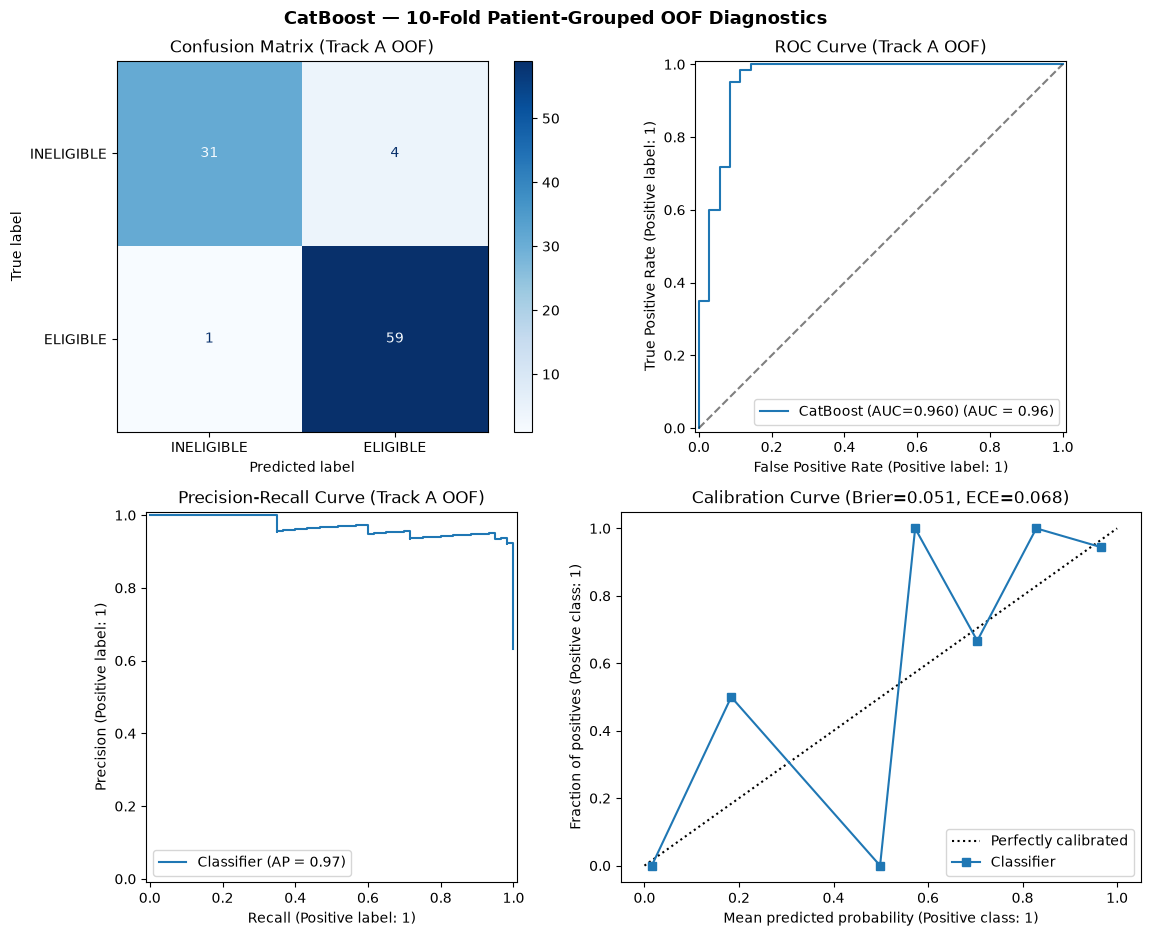

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9.5))
ConfusionMatrixDisplay.from_predictions(y_dev, (oof_a >= 0.5).astype(int), display_labels=["INELIGIBLE", "ELIGIBLE"], ax=axes[0, 0], cmap="Blues")
axes[0, 0].set_title("Confusion Matrix (Track A OOF)")

RocCurveDisplay.from_predictions(y_dev, oof_a, ax=axes[0, 1], name=f"CatBoost (AUC={overall_a['roc_auc']:.3f})")
axes[0, 1].plot([0, 1], [0, 1], "k--", alpha=0.5)
axes[0, 1].set_title("ROC Curve (Track A OOF)")

PrecisionRecallDisplay.from_predictions(y_dev, oof_a, ax=axes[1, 0])
axes[1, 0].set_title("Precision-Recall Curve (Track A OOF)")

CalibrationDisplay.from_predictions(y_dev, oof_a, n_bins=8, ax=axes[1, 1])
axes[1, 1].set_title(f"Calibration Curve (Brier={overall_a['brier_score']:.3f}, ECE={overall_a['ece']:.3f})")

fig.suptitle("CatBoost — 10-Fold Patient-Grouped OOF Diagnostics", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig(VIZ_DIR / "confusion_matrix_and_roc.png", dpi=200)
plt.show()

## 6. 10-Fold CV Stability & Track A vs Track B Performance

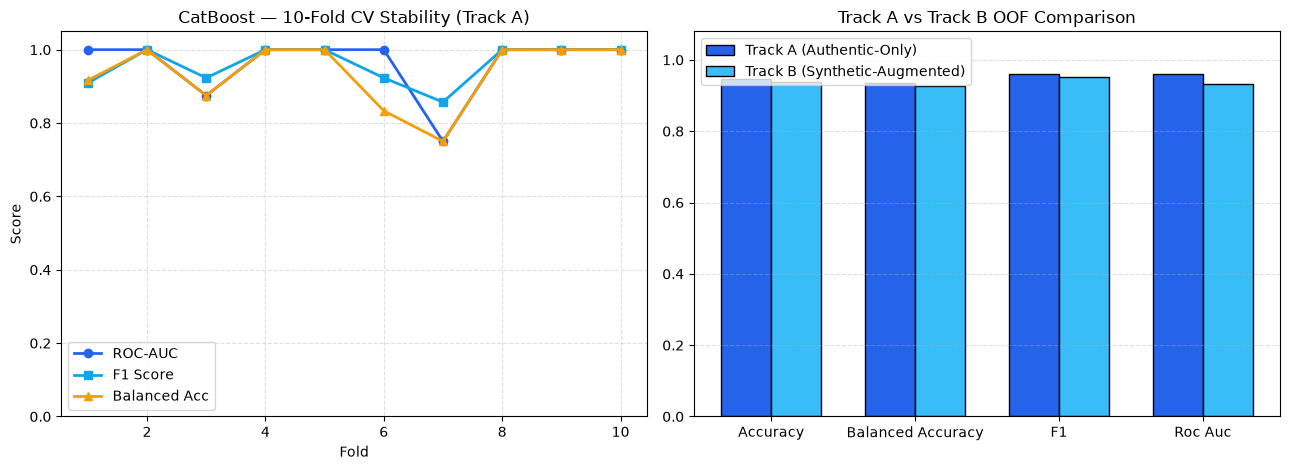

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].plot(folds_a["fold"], folds_a["roc_auc"], marker="o", label="ROC-AUC", linewidth=2, color="#2563eb")
axes[0].plot(folds_a["fold"], folds_a["f1"], marker="s", label="F1 Score", linewidth=2, color="#0ea5e9")
axes[0].plot(folds_a["fold"], folds_a["balanced_accuracy"], marker="^", label="Balanced Acc", linewidth=2, color="#f59e0b")
axes[0].set_xlabel("Fold")
axes[0].set_ylabel("Score")
axes[0].set_ylim(0, 1.05)
axes[0].set_title("CatBoost — 10-Fold CV Stability (Track A)")
axes[0].grid(True, linestyle="--", alpha=0.4)
axes[0].legend()

bar_metrics = ["accuracy", "balanced_accuracy", "f1", "roc_auc"]
x = np.arange(len(bar_metrics))
w = 0.35
axes[1].bar(x - w/2, [overall_a[m] for m in bar_metrics], width=w, label="Track A (Authentic-Only)", color="#2563eb", edgecolor="black")
axes[1].bar(x + w/2, [overall_b[m] for m in bar_metrics], width=w, label="Track B (Synthetic-Augmented)", color="#38bdf8", edgecolor="black")
axes[1].set_xticks(x)
axes[1].set_xticklabels([m.replace("_", " ").title() for m in bar_metrics])
axes[1].set_ylim(0, 1.08)
axes[1].set_title("Track A vs Track B OOF Comparison")
axes[1].grid(axis="y", linestyle="--", alpha=0.4)
axes[1].legend()

plt.tight_layout()
plt.savefig(VIZ_DIR / "cv_stability_and_tracks.png", dpi=200)
plt.show()

## 7. Top 12 Aligned Feature Importances

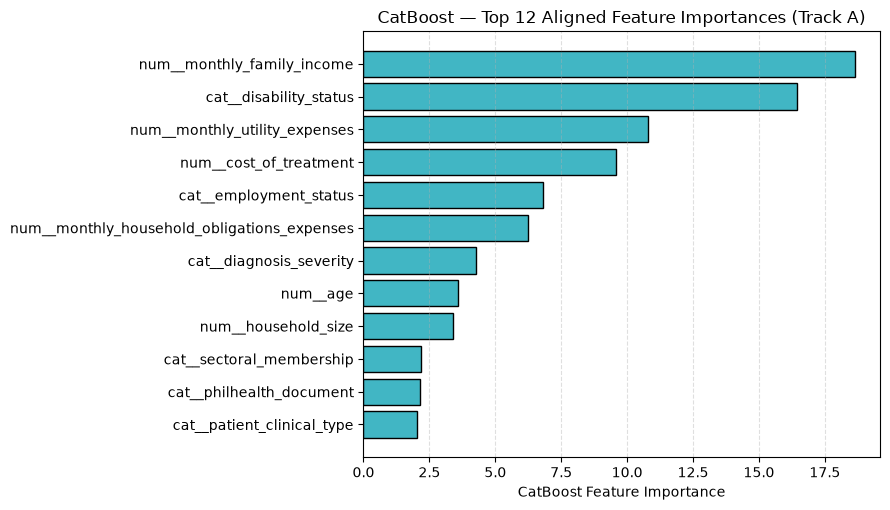

In [7]:
fig, ax = plt.subplots(figsize=(9, 5.2))
top12 = df_imp.head(12).iloc[::-1]
ax.barh(top12["feature"], top12["importance"], color="#41b6c4", edgecolor="black")
ax.set_xlabel("CatBoost Feature Importance")
ax.set_title("CatBoost — Top 12 Aligned Feature Importances (Track A)")
ax.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(VIZ_DIR / "feature_importance.png", dpi=200)
plt.show()